In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import os
import sys

# Garante que o python ache os módulos
repo_root = os.path.abspath("..")
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from tools import utils
from tools import radii_skewers 

# Estilo visual
plt.rcdefaults()
plt.style.use('tableau-colorblind10')
%matplotlib widget 

plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 11,
    'figure.titlesize': 12,
    'text.color': 'black', 
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
})


In [2]:
# --- 1. CONFIGURAÇÃO GERAL ---
SNAP_NUM = "264"
SIM_NAME = "fiducial" 
XMATCH_DIR = "../xmatchs" 

# [CONFIGURAÇÃO DA BIBLIOTECA]
# Aponta para a pasta onde você gerou todos os halos (output do script de massa)
LIBRARY_DIR = os.path.abspath("./mini_sims_library")

# [ESCOLHA DO HALO]
# Aqui você escolhe qual halo do catálogo quer analisar (0 a 451)
MATCH_INDEX = 250   

# --- 2. PARÂMETROS DA ANÁLISE ---
R200_MULTIPLIER = 0.5 

# --- 3. INICIALIZAÇÃO E BUSCA NA BIBLIOTECA ---
print(f"--> Iniciando análise para Match Index {MATCH_INDEX}...")

# 1. Descobrir o ID Real usando o Matcher
matcher = utils.HaloMatcher(XMATCH_DIR)
real_halo_id = matcher.get_halo_id(SIM_NAME, MATCH_INDEX)

# 2. Montar o caminho para a pasta específica
path_to_halo = os.path.join(LIBRARY_DIR, f"halo_{real_halo_id}")

if not os.path.exists(path_to_halo):
    raise FileNotFoundError(f"Pasta não encontrada: {path_to_halo}. Rode o script de massa primeiro.")

print(f"--> ID Real: {real_halo_id}")
print(f"--> Lendo mini-simulação em: {path_to_halo}")

# 3. Inicializar Contexto
ctx = utils.SimulationContext(path_to_halo, SNAP_NUM)
halo_finder = utils.HaloFinder(ctx)

try:
    # [TRUQUE DA MINI-SIMULAÇÃO]
    # Dentro da mini-caixa, o halo é sempre o ID 0.
    local_id = 0 
    halo_info = halo_finder.get_halo_properties(local_id)
    
    # Injetamos o ID Real de volta para os gráficos ficarem corretos
    halo_info['id'] = real_halo_id 
    
    print(f"--> Posição Central (Mpc/h): {halo_info['cm']}")
    print(f"--> BoxSize da Mini-Sim: {halo_info['box_size']:.4f} cMpc/h")
    
except Exception as e:
    print(f"ERRO CRÍTICO: {e}")
    raise e


2026-02-11 13:27:26,393 - INFO - Loading match catalog for fiducial...


--> Iniciando análise para Match Index 250...
--> ID Real: 928
--> Lendo mini-simulação em: /home/vroberto/FakeSpectra_DLAs/notebooks/mini_sims_library/halo_928
--> Posição Central (Mpc/h): [13.07026193 13.07026193 13.07026193]
--> BoxSize da Mini-Sim: 26.1405 cMpc/h


In [3]:
# --- 4. PREPARAR GEOMETRIA DOS SKEWERS ---
geom = radii_skewers.SkewerGeometry(ctx, halo_info)

# Gera os 12 skewers 
skewers_list = geom.generate_12_skewers(r_multiplier=R200_MULTIPLIER)

print(f"--> Geometria gerada: {len(skewers_list)} skewers.")
print(f"--> R200 do Halo: {geom.r200_mpc:.3f} Mpc/h")
print(f"--> Raio de Impacto: {skewers_list[0]['impact_mpc']:.3f} Mpc/h")

# --- 5. CARREGAR GÁS (Visualização) ---
# Slice pega quase a caixa toda para mostrar bem a estrutura
box_size = halo_info['box_size']
slice_thickness = box_size * 0.99 

print(f"--> Carregando Gás (Slice {slice_thickness:.2f} Mpc/h)...")
gas_loader = utils.GasLoader(ctx)

gas_map_centered = gas_loader.load_gas_slice(halo_info['cm'], box_size, slice_thickness=slice_thickness)

print(f"--> Partículas carregadas: {gas_map_centered.shape[0]}")

# --- 6. RODAR ANÁLISE DE ESPECTROS ---
print("--> Gerando espectros sintéticos...")
# Removemos isolation_factor para usar o padrão (que pega a caixa toda)
results = geom.run_analysis(skewers_list, center_mode='gas')

# Imprimir os momentos calculados (se o seu radii_skewers estiver atualizado)
print("\n--- Resumo dos Skewers ---")
for i, res in enumerate(results):
    ew = res.get('eq_width', 0)
    print(f"S{res['id']} ({res['axis_name']}): Fluxo Min={np.min(res['flux']):.4f} | EW={ew:.4f} A")

2026-02-11 13:27:26,449 - INFO - Halo 928 | R200_Crit = 0.1188 cMpc/h


--> Geometria gerada: 12 skewers.
--> R200 do Halo: 0.119 Mpc/h
--> Raio de Impacto: 0.059 Mpc/h
--> Carregando Gás (Slice 25.88 Mpc/h)...
--> Partículas carregadas: 135260
--> Gerando espectros sintéticos...
Reloading from snapshot (will save to:  /home/vroberto/FakeSpectra_DLAs/notebooks/mini_sims_library/halo_928/snapdir_264/temp_skewer_928_65540.hdf5  )


2026-02-11 13:27:26,577 - INFO - Isolation applied: R=11.88 Mpc/h. N_HI calculated.


1  sightlines. resolution:  10.015526379661999  z= 4.440892098500626e-16
Reloading from snapshot (will save to:  /home/vroberto/FakeSpectra_DLAs/notebooks/mini_sims_library/halo_928/snapdir_264/temp_skewer_928_44268.hdf5  )
1  sightlines. resolution:  10.015526379661999  z= 4.440892098500626e-16


2026-02-11 13:27:26,684 - INFO - Isolation applied: R=11.88 Mpc/h. N_HI calculated.


Reloading from snapshot (will save to:  /home/vroberto/FakeSpectra_DLAs/notebooks/mini_sims_library/halo_928/snapdir_264/temp_skewer_928_21516.hdf5  )
1  sightlines. resolution:  10.015526379661999  z= 4.440892098500626e-16


... (16 outputs left out)

2026-02-11 13:27:27,652 - INFO - Isolation applied: R=11.88 Mpc/h. N_HI calculated.


Reloading from snapshot (will save to:  /home/vroberto/FakeSpectra_DLAs/notebooks/mini_sims_library/halo_928/snapdir_264/temp_skewer_928_57979.hdf5  )
1  sightlines. resolution:  10.015526379661999  z= 4.440892098500626e-16


2026-02-11 13:27:27,760 - INFO - Isolation applied: R=11.88 Mpc/h. N_HI calculated.



--- Resumo dos Skewers ---
S1 (X): Fluxo Min=0.0000 | EW=2.1622 A
S2 (X): Fluxo Min=0.0000 | EW=1.7990 A
S3 (X): Fluxo Min=0.0000 | EW=1.6019 A
S4 (X): Fluxo Min=0.0000 | EW=1.7678 A
S5 (Y): Fluxo Min=0.0000 | EW=1.8638 A
S6 (Y): Fluxo Min=0.0000 | EW=1.7352 A
S7 (Y): Fluxo Min=0.0000 | EW=1.9031 A
S8 (Y): Fluxo Min=0.0000 | EW=1.7704 A
S9 (Z): Fluxo Min=0.0000 | EW=1.7548 A
S10 (Z): Fluxo Min=0.0000 | EW=1.8110 A
S11 (Z): Fluxo Min=0.0000 | EW=1.9554 A
S12 (Z): Fluxo Min=0.0000 | EW=1.6392 A



--> Plotando...


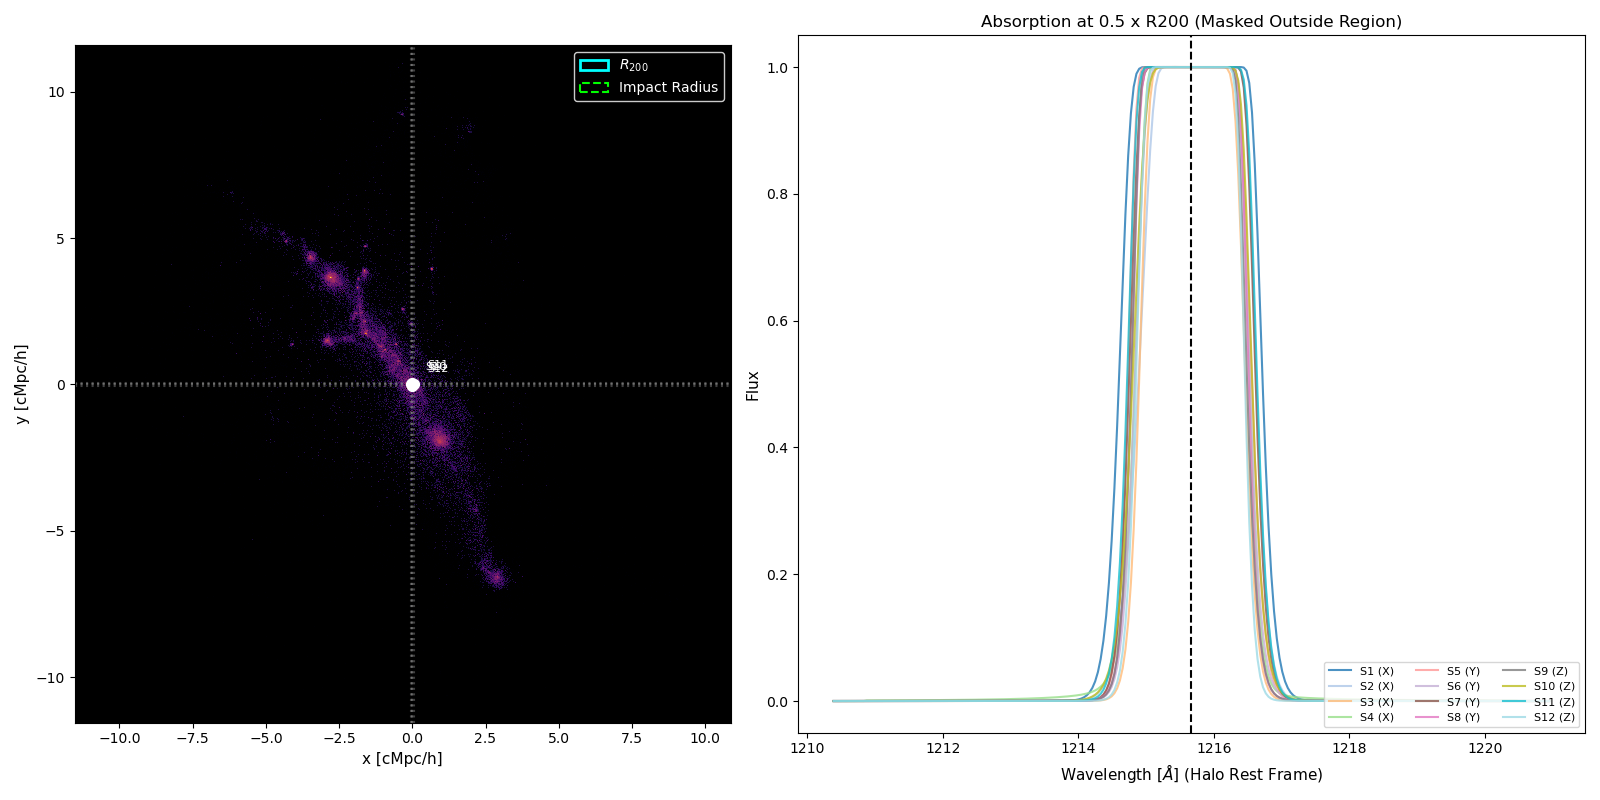

In [4]:
# --- 7. VISUALIZAÇÃO ---
print("\n--> Plotando...")
radii_skewers.RadiiVisualizer.plot_fullbox_overview(
    SIM_NAME, 
    real_halo_id, 
    geom.r200_mpc, 
    skewers_list[0]['impact_mpc'], 
    gas_map_centered, 
    results,
    box_size
)